# J2 · Gradients: fitting a super-Earth with the power-2 law

**Level:** intermediate · **Prerequisites:** [J1](J1_quickstart.ipynb) · **Run time:** ~2 min

**Covers:** a likelihood differentiated with ForwardDiff through the orbit and the light
curve, a check of the gradient against finite differences, a gradient-free optimiser against
L-BFGS, and parameter uncertainties from the Hessian (Laplace approximation).

The data are Kepler-like: 30 transits at 1-min cadence of a planet with $p = 0.02$, and
power-2 limb darkening with both coefficients free. Pizzetti supplies the exact flux
derivatives of the paper (Sect. 3.2), so the gradient is exact to rounding everywhere,
including at the contact points.

In [1]:
using Pizzetti, ForwardDiff, Optim, Random, LinearAlgebra, BenchmarkTools, Plots
include("theme.jl")

## 1. Data

The simulated data are computed without the interior series (`series_tol = 0`) and with
quadrature at the limb, so they do not share the approximations of the model fitted to them.
Globals used inside the likelihood are declared `const`, so that the compiler knows their
types (the usual Julia performance rule for global variables).

In [2]:
const truth = (t0 = 0.0, per = 10.0, rp = 0.02, a = 20.0, b = 0.4, c = 0.6, α = 0.6)
const θtrue = collect(values(truth))
const σ = 150e-6                                                    # noise per 1-min sample
const t = vec([e * truth.per + dt for dt in -0.12:(1 / 1440):0.12, e in 0:29])
model(θ) = light_curve(t, TransitParams(t0 = θ[1], per = θ[2], rp = θ[3], a = θ[4], b = θ[5],
                                         law = Power2(θ[6], θ[7])))
z0 = rsky(t, TransitParams(t0 = 0.0, per = 10.0, rp = 0.02, a = 20.0, b = 0.4, law = Power2(0.6, 0.6)))
f0 = occult(z0, 0.02, Power2(0.6, 0.6); series_tol = 0, limb = :quadrature)
const y = f0 .+ σ .* randn(Xoshiro(3), length(t))
length(t)

10380

## 2. The likelihood and its cost

The parameters are scaled to order unity for the optimisers, and $b$ enters through $|b|$.
Outside the physical range of the limb-darkening law, and for orbits that do not transit
($|b| \ge 1 + p$), the likelihood is zero ($-\ln L = \infty$).

In [3]:
const scale = [1e-4, 1e-6, 1e-4, 0.3, 0.1, 0.1, 0.1]
function nll(x)
    θ = θtrue .+ x .* scale
    θ[5] = abs(θ[5])
    (0 < θ[6] < 1 && 0 < θ[7] < 2 && θ[4] > 1 && θ[5] < 1 + θ[3]) || return oftype(x[1], Inf)
    return sum(abs2, y .- model(θ)) / (2σ^2)
end
x0 = [3.0, 2.0, 5.0, -1.3, 1.0, -1.0, 1.5]                  # a start away from the truth

tv = @belapsed nll($x0)
tg = @belapsed ForwardDiff.gradient(nll, $x0)
table(["", "time", "in likelihoods"],
      [("likelihood (orbit, light curve, χ²)", @sprintf("%.3f ms", 1e3tv), "1"),
       ("gradient, 7 parameters (ForwardDiff)", @sprintf("%.3f ms", 1e3tg), @sprintf("%.1f", tg / tv))])

,time,in likelihoods
"likelihood (orbit, light curve, χ²)",0.395 ms,1
"gradient, 7 parameters (ForwardDiff)",4.059 ms,10.3


Forward-mode differentiation carries seven partial derivatives along with every value, and
near the limb evaluates the exact derivative expressions of the paper, so a gradient costs
10–25 likelihoods, depending on the parameters (the paper, Sect. 7.4, quotes 9–15 near the
optimum). This is comparable to the $2 \times 7 = 14$ likelihoods of central differences, but
exact.

## 3. Gradient check

Against central finite differences with step $h = 10^{-4}$ (in the scaled parameters):

In [4]:
names = ["t₀", "P", "p = R_p/R_⋆", "a/R_⋆", "b", "c", "α"]
g = ForwardDiff.gradient(nll, x0)
h = 1e-4
gfd = [(nll(x0 .+ h .* (1:7 .== i)) - nll(x0 .- h .* (1:7 .== i))) / 2h for i in 1:7]
table(["parameter", "ForwardDiff", "finite differences", "relative difference"],
      [(names[i], @sprintf("%.8g", g[i]), @sprintf("%.8g", gfd[i]), sci(abs(g[i] - gfd[i]) / abs(g[i]))) for i in 1:7])

parameter,ForwardDiff,finite differences,relative difference
t₀,2.5255059,2.5255058,5.8e-08
P,0.42521228,0.42521164,1.5e-06
p = R_p/R_⋆,2.0768969,2.0768996,1.3e-06
a/R_⋆,199.65418,199.65418,4.6e-10
b,847.1223,847.12228,1.4e-08
c,29.538752,29.538737,4.9e-07
α,6.8836158,6.8836104,7.8e-07


The differences are those of the finite-difference formula, $O(h^2)$.

## 4. Optimisation: gradient-free against gradient-based

Nelder–Mead needs only likelihood values; L-BFGS uses the exact gradient (inside box
constraints, `Fminbox`). To compare them on equal terms, every likelihood evaluation is logged
with its time, so that the progress of both optimisers can be plotted against wall-clock time.

In [5]:
lower = [-Inf, -Inf, -Inf, (1.5 - 20.0) / 0.3, -Inf, (0.0 - 0.6) / 0.1, (0.0 - 0.6) / 0.1] .+ 1e-6
upper = [Inf, Inf, Inf, Inf, Inf, (1.0 - 0.6) / 0.1, (2.0 - 0.6) / 0.1] .- 1e-6
const LOG = Tuple{Float64,Float64}[]
logged(x) = (v = nll(x); x isa Vector{Float64} && push!(LOG, (time(), v)); v)
grad(x) = ForwardDiff.gradient(nll, x)
run_nm() = optimize(logged, x0, NelderMead(), Optim.Options(iterations = 20_000, g_tol = 1e-10))
run_bfgs() = optimize(logged, grad, lower, upper, x0, Fminbox(LBFGS()), Optim.Options(g_tol = 1e-6); inplace = false)
function traced(run)
    run()                                       # compile first
    empty!(LOG)
    t0 = time()
    r = run()
    return r, [(t - t0, v) for (t, v) in LOG]
end
r_nm, log_nm = traced(run_nm)
r_bfgs, log_bfgs = traced(run_bfgs)
table(["optimiser", "−ln L", "likelihood calls", "gradient calls", "time"],
      [(name, @sprintf("%.4f", Optim.minimum(r)), Optim.f_calls(r), Optim.g_calls(r), @sprintf("%.2f s", Optim.time_run(r)))
       for (name, r) in (("Nelder–Mead", r_nm), ("L-BFGS + ForwardDiff", r_bfgs))])

optimiser,−ln L,likelihood calls,gradient calls,time
Nelder–Mead,5228.0447,1086,0,1.02 s
L-BFGS + ForwardDiff,5228.0447,169,169,1.01 s


Both reach the same optimum. L-BFGS needs six times fewer likelihood evaluations, but each of
its steps also computes a gradient, so for seven parameters Nelder–Mead is faster in wall
time. The advantage of gradients grows with the number of parameters (Nelder–Mead scales
poorly beyond about ten; see [J4](J4_photodynamics.ipynb) for 21 initial conditions), and
they are what Hamiltonian Monte Carlo needs. The best value found so far, relative to the
optimum, against time:

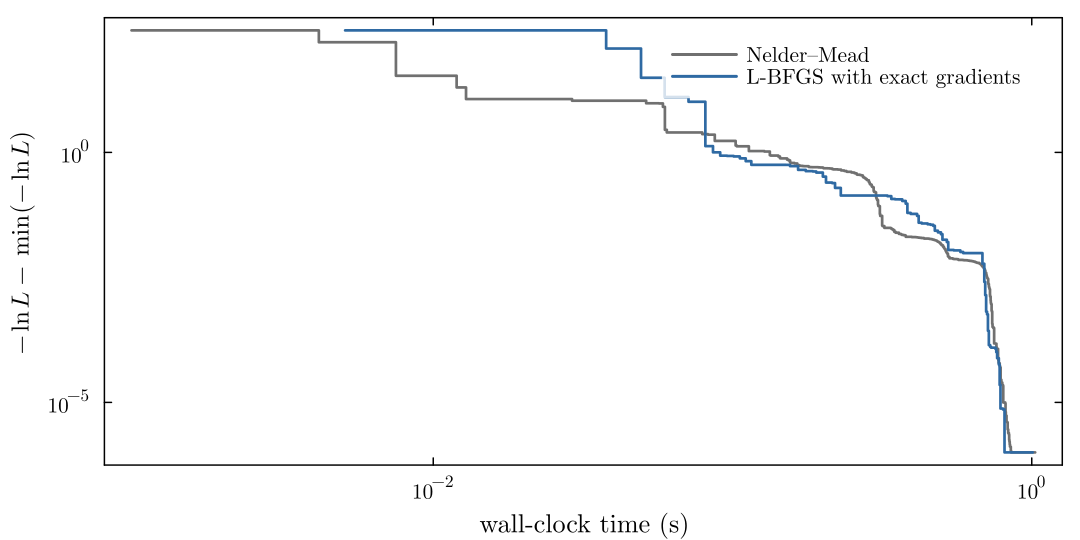

In [6]:
best = min(Optim.minimum(r_nm), Optim.minimum(r_bfgs))
progress(log) = (first.(log), max.(accumulate(min, last.(log)) .- best, 1e-6))
plt = plot(xlabel = "wall-clock time (s)", ylabel = L"-\ln L - \min(-\ln L)", yscale = :log10,
           xscale = :log10, legend = :topright, size = (720, 360))
plot!(plt, progress(log_nm)..., label = "Nelder–Mead", color = COLORS.out, seriestype = :steppost)
plot!(plt, progress(log_bfgs)..., label = "L-BFGS with exact gradients", color = COLORS.series,
      seriestype = :steppost)
plt

## 5. Uncertainties from the Hessian

Near the optimum the posterior is approximately Gaussian, with covariance $H^{-1}$, the
inverse Hessian of $-\ln L$ (Laplace approximation). ForwardDiff computes $H$ with nested
dual numbers.

In [7]:
xbest = Optim.minimizer(r_bfgs)
H = ForwardDiff.hessian(nll, xbest)
Σ = inv(Symmetric(H))
θbest = θtrue .+ xbest .* scale
θbest[5] = abs(θbest[5])
δ = sqrt.(diag(Σ)) .* scale
table(["parameter", "best fit", "± (Hessian)", "truth", "(fit − truth)/σ"],
      [(names[i], @sprintf("%.8g", θbest[i]), @sprintf("%.2g", δ[i]), @sprintf("%.8g", θtrue[i]),
        @sprintf("%+.2f", (θbest[i] - θtrue[i]) / δ[i])) for i in 1:7])

parameter,best fit,± (Hessian),truth,(fit − truth)/σ
t₀,-7.4007353e-05,0.00017,0,-0.43
P,10.000015,1.1e-05,10,+1.39
p = R_p/R_⋆,0.020158573,0.00016,0.02,+0.97
a/R_⋆,19.876187,0.94,20,-0.13
b,0.41721449,0.093,0.4,+0.19
c,0.48669233,0.091,0.6,-1.25
α,0.81616637,0.25,0.6,+0.88


The deviations from the truth are of order one standard deviation, as they should be. A
400-ppm transit constrains the limb darkening only weakly: for other noise realisations the
optimum can lie on the boundary $c \to 1$, where the likelihood is not locally Gaussian and the
Laplace approximation fails; the posterior is then sampled with MCMC (as in the paper,
Sect. 7.4). The correlation matrix shows the familiar degeneracies of transit fits:
$a/R_\star$ with $b$ and $p$, and the two limb-darkening parameters with each other.

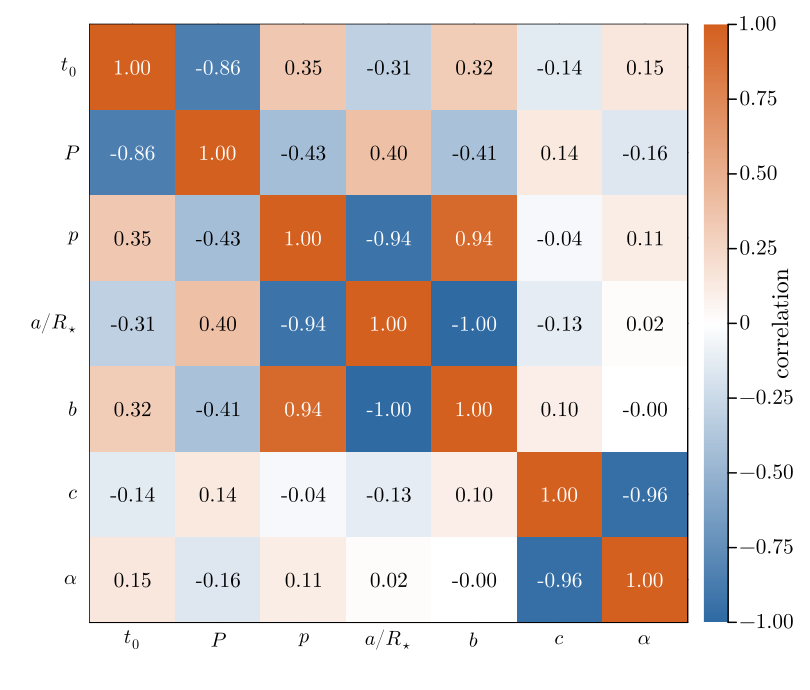

In [8]:
C = Σ ./ sqrt.(diag(Σ) * diag(Σ)')
labels = [L"t_0", L"P", L"p", L"a/R_\star", L"b", L"c", L"\alpha"]
plt = heatmap(1:7, 1:7, C, c = cgrad([COLORS.series, :white, COLORS.limb]), clims = (-1, 1), yflip = true,
              xticks = (1:7, labels), yticks = (1:7, labels), aspect_ratio = 1, xlims = (0.5, 7.5),
              ylims = (0.5, 7.5), size = (540, 460), colorbar_title = "correlation")
for i in 1:7, j in 1:7
    annotate!(plt, j, i, text(@sprintf("%.2f", C[i, j]), 9, "Computer Modern", abs(C[i, j]) > 0.6 ? :white : :black))
end
plt

## 6. The fit

All 30 transits folded on the best-fitting ephemeris, with the data averaged in 10-min bins:

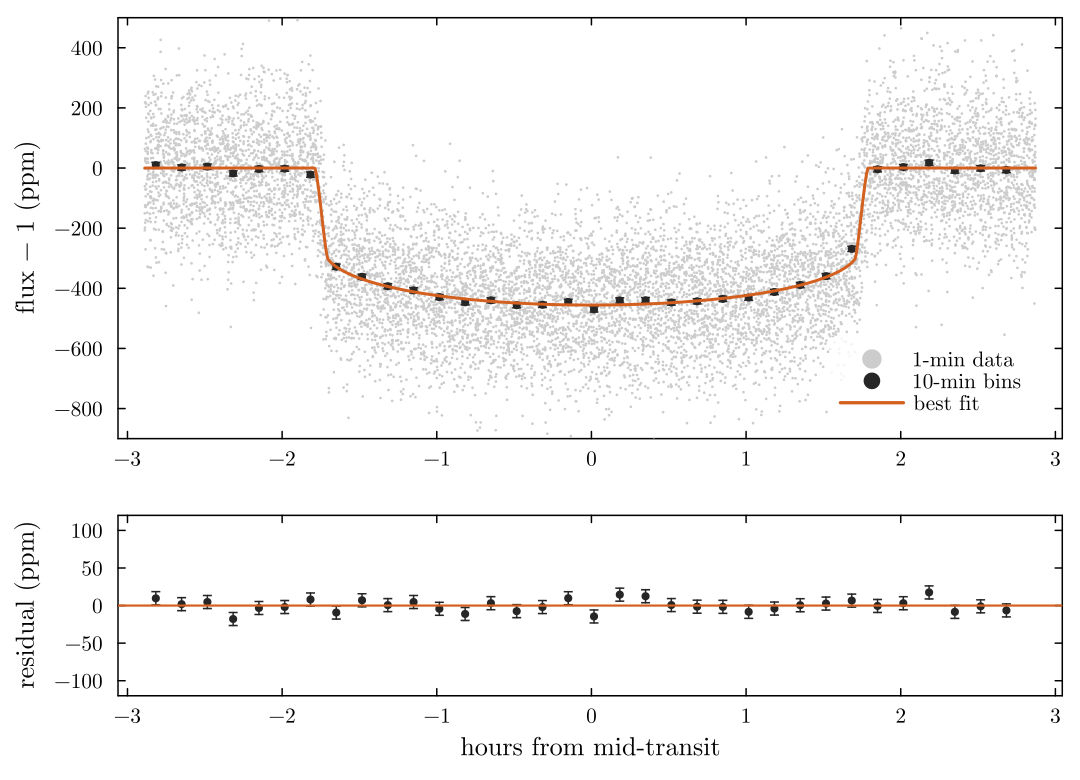

In [9]:
fbest = model(θbest)
phase = 24 .* (mod.(t .- θbest[1] .+ θbest[2] / 2, θbest[2]) .- θbest[2] / 2)        # hours
edges = -2.9:(1 / 6):2.9
bins = [findall(e .<= phase .< e + 1 / 6) for e in edges[1:end-1]]
centres = edges[1:end-1] .+ 1 / 12
binned(v) = [sum(v[i]) / length(i) for i in bins]
err = σ ./ sqrt.(length.(bins))
o = sortperm(phase)
p1 = scatter(phase, 1e6 .* (y .- 1), ms = 1, msw = 0, color = :gray80, label = "1-min data")
scatter!(p1, centres, 1e6 .* (binned(y) .- 1), yerror = 1e6 .* err, ms = 3, color = COLORS.ink, msc = COLORS.ink,
         label = "10-min bins")
plot!(p1, phase[o], 1e6 .* (fbest[o] .- 1), color = COLORS.limb, lw = 2, label = "best fit",
      ylabel = "flux − 1 (ppm)", ylims = (-900, 500), legend = :bottomright)
p2 = scatter(centres, 1e6 .* binned(y .- fbest), yerror = 1e6 .* err, ms = 3, color = COLORS.ink, msc = COLORS.ink,
             label = "", ylabel = "residual (ppm)", xlabel = "hours from mid-transit", ylims = (-120, 120))
hline!(p2, [0], color = COLORS.limb, lw = 1.5, label = "")
plt = plot(p1, p2, layout = grid(2, 1, heights = [0.7, 0.3]), link = :x, size = (720, 520))
plt

## What you learned

- the whole model (orbit, light curve, χ²) is differentiable with ForwardDiff, and the
  gradient agrees with finite differences to their own accuracy;
- declare globals used in a likelihood `const` (here a factor of two in speed);
- L-BFGS with exact gradients needs far fewer likelihood evaluations than Nelder–Mead; whether
  it is also faster depends on the number of parameters and the cost of a gradient;
- the Hessian at the optimum gives Laplace-approximation uncertainties and correlations.

**Next:** [J3 · Precision and rigour](J3_precision_and_rigour.ipynb), or
[J4 · Photodynamics](J4_photodynamics.ipynb) for gradients through an N-body code.